<h3 style="font-weight:bold;color:darkslateblue;">Figure Subfigures</h3>

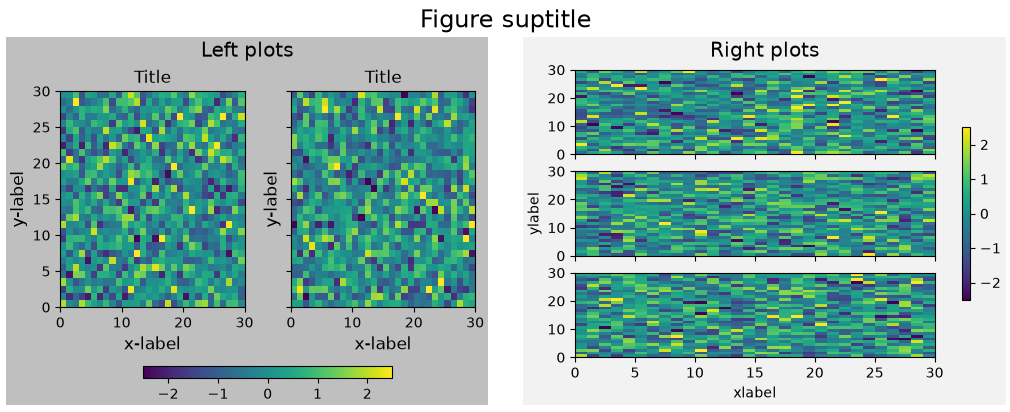

In [11]:
import matplotlib.pyplot as plt
import numpy as np

from matplotlib.axes import Axes
from matplotlib.collections import QuadMesh


def example_plot(ax: Axes, fontsize: float = 12, hide_labels: bool = False) -> QuadMesh:
    pc = ax.pcolormesh(np.random.randn(30, 30), vmin=-2.5, vmax=2.5)

    if not hide_labels:
        ax.set_xlabel("x-label", fontsize=fontsize)
        ax.set_ylabel("y-label", fontsize=fontsize)
        ax.set_title("Title", fontsize=fontsize)
    return pc


np.random.seed(19680808)

# gridspec inside gridspec
fig = plt.figure(figsize=(10, 4), layout="constrained")
subfigs = fig.subfigures(1, 2, wspace=0.07)

axsLeft = subfigs[0].subplots(1, 2, sharey=True)
axsRight = subfigs[1].subplots(3, 1, sharex=True)
subfigs[0].set_facecolor("0.75")

for ax in axsLeft:
    pc = example_plot(ax)

subfigs[0].suptitle("Left plots", fontsize="x-large")
subfigs[0].colorbar(pc, shrink=0.6, ax=axsLeft, location="bottom")

for nn, ax in enumerate(axsRight):
    pc = example_plot(ax, hide_labels=True)

    if nn == 2:
        ax.set_xlabel("xlabel")
    if nn == 1:
        ax.set_ylabel("ylabel")

subfigs[1].set_facecolor("0.95")
subfigs[1].colorbar(pc, shrink=0.6, ax=axsRight)
subfigs[1].suptitle("Right plots", fontsize="x-large")

fig.suptitle("Figure suptitle", fontsize="xx-large")
plt.show()

<h3 style="font-weight:bold;color:darkslateblue;">Mix Subplots and Subfigures with gridspec</h3>

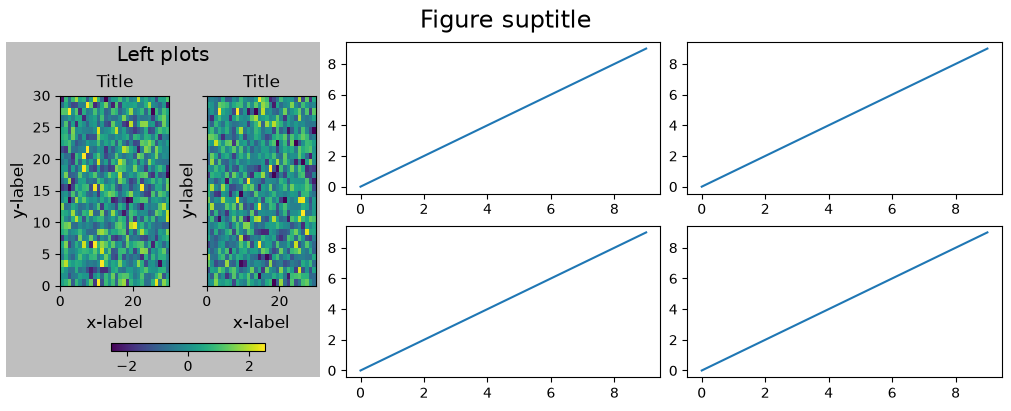

In [16]:
fig, axs = plt.subplots(2, 3, figsize=(10, 4), layout="constrained")
gridspec = axs[0, 0].get_subplotspec().get_gridspec()

# Clear the left column for the subfigure:
for a in axs[:, 0]:
    a.remove()

# Plot data in remaining Axes:
for a in axs[:, 1:].flat:
    a.plot(np.arange(10))

# Make the subfigure in the empty gridspec slots:
subfig = fig.add_subfigure(gridspec[:, 0])

axsLeft = subfig.subplots(1, 2, sharey=True)
subfig.set_facecolor("0.75")

for ax in axsLeft:
    pc = example_plot(ax)

subfig.suptitle("Left plots", fontsize="x-large")
subfig.colorbar(pc, shrink=0.6, ax=axsLeft, location="bottom")

fig.suptitle("Figure suptitle", fontsize="xx-large")
plt.show()

<h3 style="font-weight:bold;color:darkslateblue;">Subfigures with different widths and heights</h3>

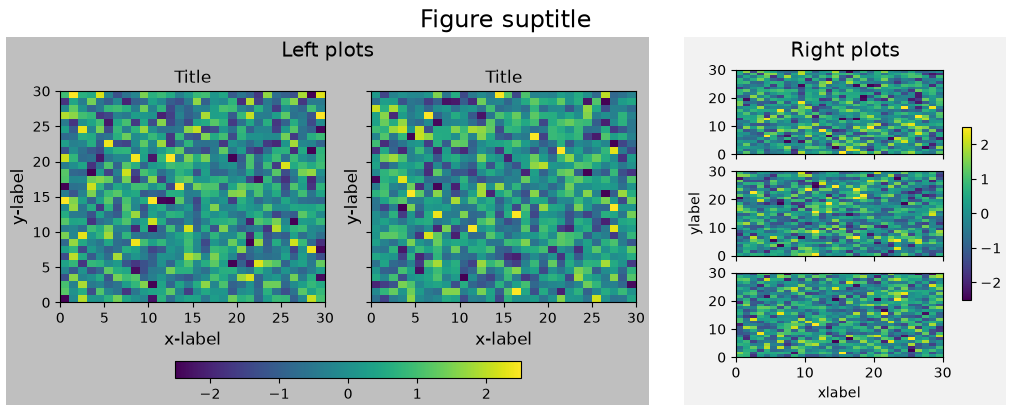

In [17]:
fig = plt.figure(figsize=(10, 4), layout="constrained")
subfigs = fig.subfigures(1, 2, wspace=0.07, width_ratios=[2, 1])

axsLeft = subfigs[0].subplots(1, 2, sharey=True)
axsRight = subfigs[1].subplots(3, 1, sharex=True)
subfigs[0].set_facecolor("0.75")

for ax in axsLeft:
    pc = example_plot(ax)

subfigs[0].suptitle("Left plots", fontsize="x-large")
subfigs[0].colorbar(pc, shrink=0.6, ax=axsLeft, location="bottom")

for nn, ax in enumerate(axsRight):
    pc = example_plot(ax, hide_labels=True)

    if nn == 2:
        ax.set_xlabel("xlabel")
    if nn == 1:
        ax.set_ylabel("ylabel")

subfigs[1].set_facecolor("0.95")
subfigs[1].colorbar(pc, shrink=0.6, ax=axsRight)
subfigs[1].suptitle("Right plots", fontsize="x-large")

fig.suptitle("Figure suptitle", fontsize="xx-large")
plt.show()

<h3 style="font-weight:bold;color:darkslateblue;">Nested Subfigures</h3>

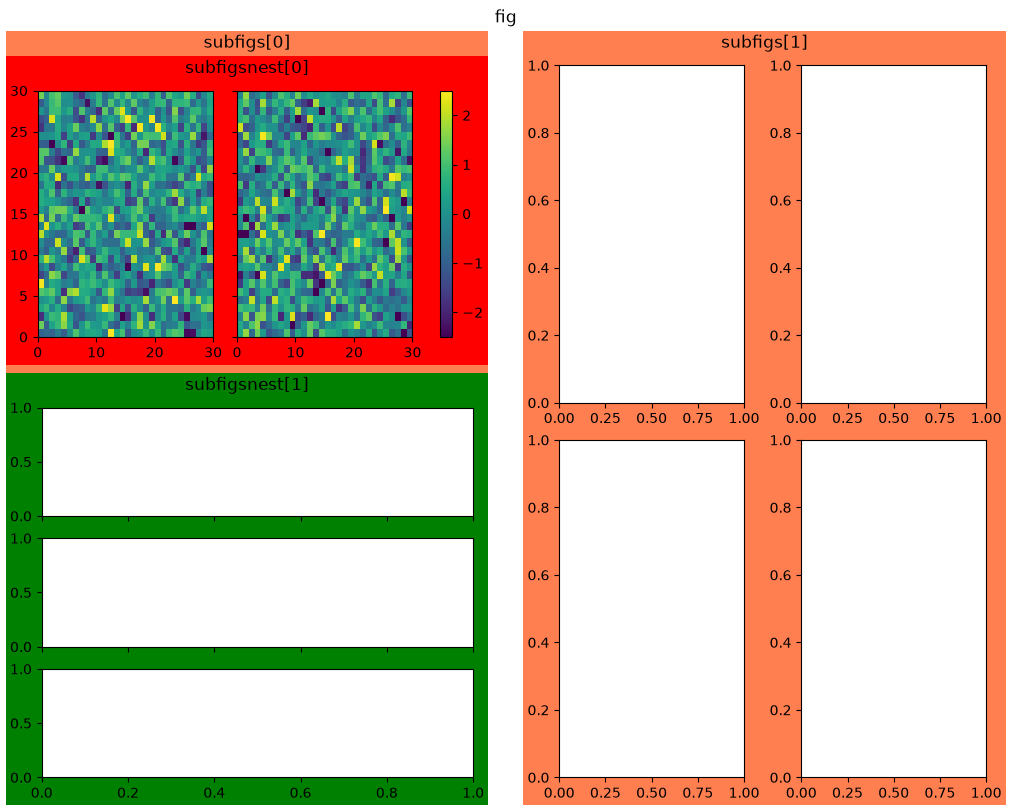

In [24]:
fig = plt.figure(figsize=(10, 8), layout="constrained")
fig.suptitle("fig")
subfigs = fig.subfigures(1, 2, wspace=0.07)

subfigs[0].set_facecolor("coral")
subfigs[0].suptitle("subfigs[0]")

subfigs[1].set_facecolor("coral")
subfigs[1].suptitle("subfigs[1]")

subfigsnest = subfigs[0].subfigures(2, 1, height_ratios=[1, 1.4])
subfigsnest[0].suptitle("subfigsnest[0]")
subfigsnest[0].set_facecolor("r")
axsnest0 = subfigsnest[0].subplots(1, 2, sharey=True)

for nn, ax in enumerate(axsnest0):
    pc = example_plot(ax, hide_labels=True)

subfigsnest[0].colorbar(pc, ax=axsnest0)

subfigsnest[1].suptitle("subfigsnest[1]")
subfigsnest[1].set_facecolor("g")
axsnest1 = subfigsnest[1].subplots(3, 1, sharex=True)
axsRight = subfigs[1].subplots(2, 2)

plt.show()